# Analyse exploratoire des avis BoursoBank (Trustpilot)

Objectif : décrire les avis collectés (notes, dates, types d'avis, textes)
avant l'analyse de sentiment. Données issues de `data/reviews.db`.

# Importation et chargement 

In [3]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

connection = sqlite3.connect("../data/reviews.db")
df = pd.read_sql_query("SELECT * FROM reviews", connection)
connection.close()
df.head()

,review_id,source_id,title,text,rating,published_date,author,country,language,verification_level,has_reply,likes,collected_at
0,6adc81418e3448fcb79d0b8e,1,Facilité,App. Fluide et facile à l'utilisation.,5,2026-10-24T11:58:25.000Z,Heythem T,FR,fr,invited,0,0,2026-10-24 12:47:53
1,6adc6be504f96ceeeb1b4103,1,Très simple et intuitif,Très simple et intuitif,5,2026-10-24T10:27:17.000Z,Maud P,FR,fr,invited,0,0,2026-10-24 12:47:53
2,6adc6b00626aa29c044db96f,1,Je suis très déçue des frais de non…,Je suis très déçue des frais de non activité d...,1,2026-10-24T10:23:28.000Z,Blandine HOARAU,FR,fr,invited,0,0,2026-10-24 12:47:53
3,6adc601c0af89bf889c8cf76,1,l’absence de frais mensuels,"l’absence de frais mensuels, c’est un vrai plu...",5,2026-10-24T09:37:00.000Z,Molka Z,FR,fr,invited,0,0,2026-10-24 12:47:53
4,6adc5fcc85c9a761245b5f48,1,Impossible d'effectuer librement des…,Impossible d'effectuer librement des virements...,1,2026-10-24T09:35:40.000Z,xxxxx Christophe,FR,fr,invited,0,0,2026-10-24 12:47:53


In [4]:
print("Dimensions :", df.shape)
df.info()
df.isna().sum()

Dimensions : (200, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   review_id           200 non-null    object
 1   source_id           200 non-null    int64 
 2   title               200 non-null    object
 3   text                200 non-null    object
 4   rating              200 non-null    int64 
 5   published_date      200 non-null    object
 6   author              200 non-null    object
 7   country             200 non-null    object
 8   language            200 non-null    object
 9   verification_level  200 non-null    object
 10  has_reply           200 non-null    int64 
 11  likes               200 non-null    int64 
 12  collected_at        200 non-null    object
dtypes: int64(4), object(9)
memory usage: 20.4+ KB


review_id             0
source_id             0
title                 0
text                  0
rating                0
published_date        0
author                0
country               0
language              0
verification_level    0
has_reply             0
likes                 0
collected_at          0
dtype: int64

# Nettoyage 

In [5]:
df["published_date"] = pd.to_datetime(df["published_date"], utc=True)
df["has_reply"] = df["has_reply"].astype(bool)
df["text"] = df["text"].fillna("").str.strip()
df["text_length"] = df["text"].str.split().str.len()

print("Langues :", df["language"].value_counts().to_dict())
df = df[(df["language"] == "fr") & (df["text"] != "")]
print("Avis conservés après nettoyage :", len(df))

Langues : {'fr': 200}
Avis conservés après nettoyage : 200


# Distribution des Notes

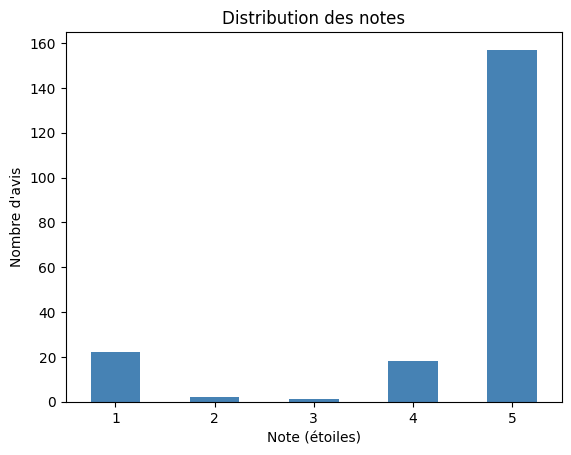

In [6]:
rating_counts = df["rating"].value_counts().reindex(range(1, 6), fill_value=0)

ax = rating_counts.plot(kind="bar", color="steelblue")
ax.set_title("Distribution des notes")
ax.set_xlabel("Note (étoiles)")
ax.set_ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.show()

# Observations

- La distribution est très **polarisée, en forme de « J »** : 157 avis sur 200
  (environ 78 %) donnent 5 étoiles, et 22 avis (11 %) donnent 1 étoile.
- Les notes intermédiaires sont quasiment absentes : 2 et 3 étoiles ne
  représentent que 3 avis au total. C'est typique des plateformes d'avis : les
  clients écrivent surtout quand ils sont très satisfaits ou très mécontents.
- La **moyenne de 4,43 est donc trompeuse** : elle ne décrit pas un client
  « type » moyennement satisfait, mais résume deux groupes opposés, une large
  majorité ravie et une minorité très insatisfaite.
- Hypothèse à vérifier dans la suite : la forte proportion de 5 étoiles
  pourrait s'expliquer par les avis **sollicités par BoursoBank** (invitations
  envoyées aux clients), qui seraient bien plus positifs que les avis spontanés.

# Evolution Temporelle

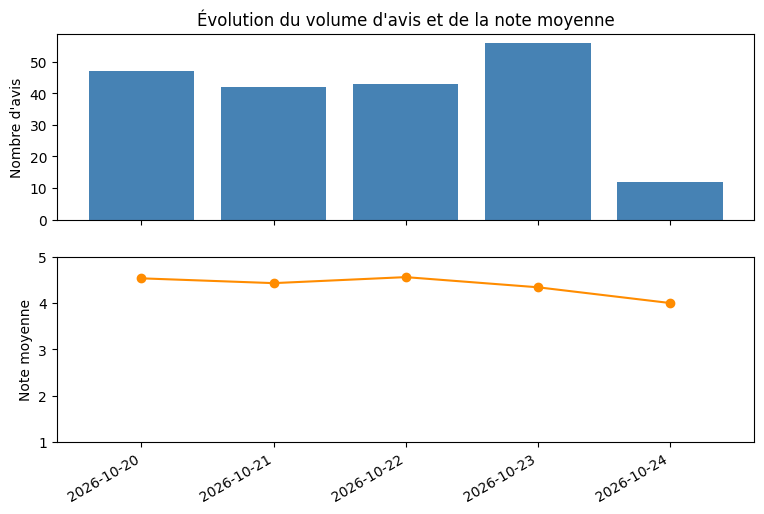

Période couverte : du 20/10/2026 au 24/10/2026


In [7]:
FREQUENCY = "D"  # "D" = par jour, "W" = par semaine, "MS" = par mois

evolution = (
    df.set_index("published_date")
    .resample(FREQUENCY)["rating"]
    .agg(["count", "mean"])
)

fig, (ax_count, ax_mean) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax_count.bar(evolution.index, evolution["count"], color="steelblue")
ax_count.set_ylabel("Nombre d'avis")
ax_count.set_title("Évolution du volume d'avis et de la note moyenne")
ax_mean.plot(evolution.index, evolution["mean"], marker="o", color="darkorange")
ax_mean.set_ylabel("Note moyenne")
ax_mean.set_ylim(1, 5)
fig.autofmt_xdate()
plt.show()

print(f"Période couverte : du {df['published_date'].min():%d/%m/%Y} au {df['published_date'].max():%d/%m/%Y}")

# Observations : 

- Les 200 avis collectés couvrent seulement **5 jours, du 20 au 24 octobre 2026**.
  BoursoBank reçoit en effet environ **40 à 55 avis par jour**, soit plus de
  1 000 par mois. Comme Trustpilot n'affiche que les 200 avis les plus récents
  aux visiteurs non connectés, notre échantillon ne remonte pas plus loin.
- Le faible volume du 24 octobre (12 avis) ne traduit pas une baisse d'activité :
  la collecte a eu lieu ce jour-là, la journée était donc **incomplète**.
- La note moyenne est **stable, autour de 4,4 à 4,6** sur la période. La légère
  baisse du 24 octobre (environ 4,0) n'est pas significative : elle repose sur
  seulement 12 avis, et quelques avis négatifs suffisent à faire bouger la moyenne.
- **Limite de l'analyse :** sur 5 jours, on ne peut pas parler de tendance.
  Pour suivre une vraie évolution sur plusieurs semaines, la collecte sera
  relancée régulièrement ; la base SQLite accumulera les nouveaux avis sans
  doublons, et le regroupement pourra alors passer à la semaine (`FREQUENCY = "W"`).

# Collecte d'avis spontanés 

                    count  mean
verification_level             
invited               178  4.74
not-verified           22  1.95


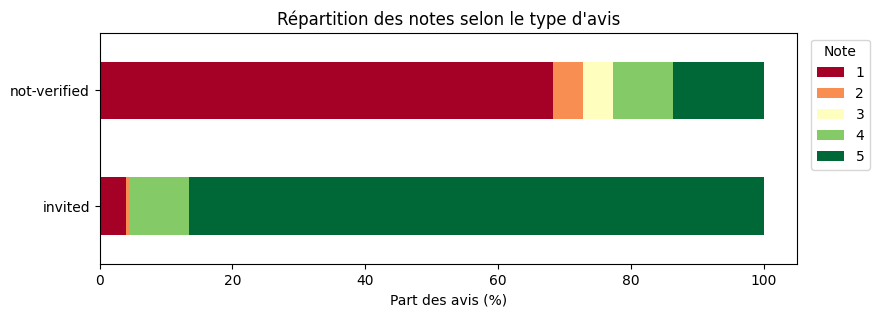

In [8]:
print(df.groupby("verification_level")["rating"].agg(["count", "mean"]).round(2))

distribution_by_type = pd.crosstab(df["verification_level"], df["rating"], normalize="index") * 100

ax = distribution_by_type.plot(kind="barh", stacked=True, colormap="RdYlGn", figsize=(9, 3))
ax.set_xlabel("Part des avis (%)")
ax.set_ylabel("")
ax.set_title("Répartition des notes selon le type d'avis")
ax.legend(title="Note", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

# Observations 

- L'écart est spectaculaire : les **178 avis sollicités** par BoursoBank
  (`invited`) ont une note moyenne de **4,74**, contre **1,95** pour les
  **22 avis spontanés** (`not-verified`).
- Les deux distributions sont presque inversées. Environ **86 % des avis
  sollicités donnent 5 étoiles**, alors qu'environ **68 % des avis spontanés
  (15 sur 22) donnent 1 étoile**.
- Comme les avis sollicités représentent **89 % de l'échantillon**, ce sont eux
  qui déterminent la note globale de 4,43. La note affichée reflète donc surtout
  la politique d'invitation de l'entreprise.
- Deux lectures sont possibles, et elles ne s'excluent pas :
  - un **biais de sélection** : si les invitations sont envoyées après une
    interaction réussie (ouverture de compte, par exemple), elles touchent en
    priorité des clients satisfaits ;
  - à l'inverse, les avis spontanés sont surtout écrits par des clients
    **motivés par un problème**. Les invitations donnent la parole à une
    « majorité silencieuse » satisfaite qui n'aurait pas écrit d'elle-même.
- **Limites :** 22 avis spontanés constituent un petit échantillon, et
  « not-verified » signifie seulement que Trustpilot n'a pas pu vérifier
  l'expérience client, pas que l'avis est faux.
- Pour la suite : il sera intéressant de comparer le **vocabulaire** et le
  **score de sentiment** de ces deux groupes, et de pouvoir les filtrer
  séparément dans le dashboard.

# la longueur des avis selon la note
On utilise la médiane plutôt que la moyenne, car quelques avis très longs suffiraient à fausser une moyenne. Hypothèse classique à vérifier : les clients mécontents écrivent plus longuement, car ils détaillent leur problème.

In [9]:
df.groupby("rating")["text_length"].median()

rating
1     54.0
2    137.5
3     48.0
4      7.5
5      4.0
Name: text_length, dtype: float64

# Les mots les plus fréquents

In [10]:
import re
from collections import Counter

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words("french")) | {
    "très", "plus", "tout", "tous", "cette", "fait", "faire", "être", "avoir", "ça",
    "aussi", "comme", "donc", "car", "sans", "depuis", "encore",
    "bourso", "boursobank", "boursorama", "banque",
}


def top_words(texts, n=15):
    """Renvoie les n mots les plus fréquents d'une série de textes, hors mots vides et mots de moins de 3 lettres."""
    words = []
    for text in texts:
        for word in re.findall(r"[a-zàâäçéèêëîïôöùûüÿœæ]+", text.lower()):
            if len(word) > 2 and word not in STOPWORDS:
                words.append(word)
    return Counter(words).most_common(n)


positive_words = top_words(df.loc[df["rating"] >= 4, "text"])
negative_words = top_words(df.loc[df["rating"] <= 2, "text"])

pd.DataFrame({
    "Avis positifs (4-5)": pd.Series([f"{word} ({count})" for word, count in positive_words]),
    "Avis négatifs (1-2)": pd.Series([f"{word} ({count})" for word, count in negative_words]),
})

,Avis positifs (4-5),Avis négatifs (1-2)
0,rapide (38),carte (25)
1,simple (24),compte (15)
2,facile (22),demande (15)
3,bien (20),service (11)
4,efficace (17),client (11)
5,rapidité (16),problème (10)
6,bonne (13),impossible (8)
7,merci (13),réponse (8)
8,utilisation (12),visa (8)
9,pratique (9),toujours (7)


# Nuage de mots d'avis négatifs

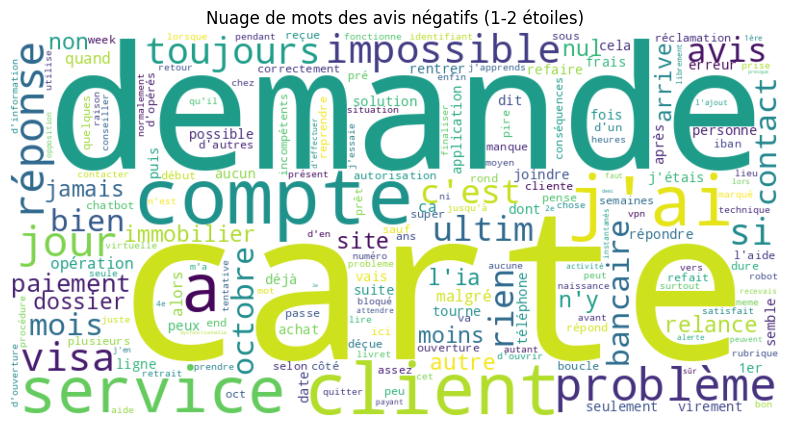

In [12]:
from wordcloud import WordCloud

negative_text = " ".join(df.loc[df["rating"] <= 2, "text"]).lower()
cloud = WordCloud(
    width=800, height=400, background_color="white",
    stopwords=STOPWORDS, collocations=False,
).generate(negative_text)

plt.figure(figsize=(10, 5))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Nuage de mots des avis négatifs (1-2 étoiles)")
plt.show()

## Observations : vocabulaire des avis négatifs

Quatre grands sujets de mécontentement se dégagent :

- **La carte bancaire** : « carte » est le mot dominant, associé à « visa »,
  « ultim » (l'offre de carte de BoursoBank), « paiement » et « bloqué ».
- **Le service client** : « service », « client », « réponse », « contact »,
  « joindre », « relance ». Les clients se plaignent surtout de ne pas réussir
  à obtenir de réponse.
- **Le sentiment d'impasse** : « impossible », « problème », « toujours »,
  « jamais », « rien ». Les avis décrivent des situations bloquées qui
  s'éternisent, plus que des incidents ponctuels.
- **L'automatisation** : « l'ia », « chatbot », « robot ». Une partie des
  clients reproche de ne pas pouvoir parler à un conseiller humain.

On repère aussi des démarches précises : ouverture de compte, dossier de
crédit immobilier, virements.

**Limite :** ce nuage repose sur seulement 24 avis négatifs. Il donne des
pistes, pas des conclusions générales.

## Conclusion de l'analyse exploratoire

1. **Une satisfaction apparente très élevée** : note moyenne de 4,43, avec 78 %
   d'avis à 5 étoiles. Mais la distribution en « J » montre deux populations
   opposées plutôt qu'une satisfaction moyenne.
2. **Un effet majeur du mode de collecte des avis** : les avis sollicités par
   BoursoBank (89 % de l'échantillon, moyenne 4,74) sont bien plus positifs que
   les avis spontanés (moyenne 1,95). La note globale reflète donc en grande
   partie la politique d'invitation de l'entreprise.
3. **Des irritants clairement identifiés** : la carte bancaire, l'accessibilité
   du service client et le recours à l'IA ou aux chatbots dominent les avis
   négatifs.
4. **Une limite temporelle** : les 200 avis ne couvrent que 5 jours. Les
   collectes régulières permettront d'étudier l'évolution sur plusieurs semaines.

**Étape suivante (séance 6) :** calculer un score de sentiment pour chaque avis,
le comparer à la note donnée par le client, et vérifier si le texte des avis
spontanés est aussi négatif que leur note le laisse penser.